# Lecture 2: Random Number Generation & Statistics

Introduce the main computational concepts and develop the mathematical foundations of the numerical methods, explaining how they are derived and the ideas behind them.


## Part A and Part B — Theory and Numerical Methods and Guided Implementation

The following two topics are developed through theory and guided examples:

### 1. Random Number Generation 

1. Linear Congruential Generator

2. Inverse Transform Method

### 2. The Statistics of Random Processes




## Introduction

Many physical systems are fundamentally **stochastic** — radioactive decay, thermal
noise, the scattering of photons, the diffusion of a dye molecule in water. To study
these systems computationally we need two things:

1. A way to **generate** random numbers on a computer.
2. A way to **quantify how much to trust** any conclusion we draw from a
   simulation that uses randomness — because every run gives a slightly
   different answer.

This lecture builds both pieces. We will:
- Learn how (pseudo-)random numbers are generated, and how to check whether a
  generator is any good.
- Build up the statistical toolkit — mean, variance, how these converge as we
  collect more data, and how to choose simulation parameters so we can be
  confident in our results — starting from first principles rather than
  quoting formulas.
- Apply all of this to a genuine physical system: the random decay of
  unstable nuclei.

This statistical toolkit is not a one-off aside — it is exactly what you will
need in **Lecture 2** (the random walker itself) and again in the Monte Carlo
and Ising Model topics later in the course, so it is worth building carefully
here.

## Section 1.1: Generating Random Numbers

### True randomness vs. pseudorandomness

A **hardware random number generator** uses a physical process that is
inherently unpredictable — radioactive decay, thermal (Johnson) noise, or
quantum measurement — to produce numbers with no algorithmic pattern. The
video below shows one classic approach: using the random timing of
radioactive decay events (detected via a Geiger counter) to generate random
bits.

> 🎥 **Watch:** [Using radiation to generate random numbers](https://www.youtube.com/watch?v=lydhprdvVmc)
>
> A hardware random-number generator in action: it detects individual
> radioactive decays and converts the unpredictable gaps between them into
> random bits. Nothing about the sequence is computed — the randomness comes
> from quantum mechanics itself.

Interestingly, radioactive decay — the very physical process we will
simulate later in this lecture — is itself a source of *true* randomness.

For most simulation work, however, hardware generators are impractical (they
require special equipment and are typically slow). Instead we use
**pseudorandom number generators (PRNGs)**: deterministic algorithms that
produce sequences of numbers which *look* statistically random (pass
statistical tests for randomness) but are fully determined by a starting
value called the **seed**. Given the same seed, a PRNG always produces the
same sequence — this reproducibility is actually a *feature* for scientific
computing, since it lets you rerun and debug a simulation exactly.

### Random numbers in Python

Python's built-in `random` module provides simple pseudorandom generation:

1. `random.random()` — a random float in $[0,1)$.
2. `random.randint(a, b)` — a random integer in $[a,b]$ (inclusive).
3. `random.uniform(a, b)` — a random float in $[a,b]$.
4. `random.choice(seq)` — a random element from a sequence.
5. `random.seed(value)` — fixes the seed for reproducibility.

In [7]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Basic usage of Python's random module
rand_float = random.random()
print(f"Random float in [0,1): {rand_float:.4f}")

rand_int = random.randint(1, 10)
print(f"Random integer in [1,10]: {rand_int}")

rand_uniform = random.uniform(5, 15)
print(f"Random float in [5,15]: {rand_uniform:.4f}")

random.seed(3435)
seeded_random = random.random()
print(f"Random float with seed 3435: {seeded_random:.6f}")

# Reproducibility check: same seed -> same number
random.seed(3435)
seeded_random_again = random.random()
print(f"Same seed again: {seeded_random_again:.6f} (should match the line above)")

Random float in [0,1): 0.2037
Random integer in [1,10]: 6
Random float in [5,15]: 12.1666
Random float with seed 3435: 0.005950
Same seed again: 0.005950 (should match the line above)


### ⚛️ Physics Application: simulating measurement noise

Every real measurement in a physics lab has some random uncertainty. Suppose
a sensor reads the position of a particle as $x_{\text{true}} = 2.00\,$, but
the instrument has noise of $\pm 0.05\,$ (uniformly distributed). We can
simulate ten such noisy measurements:

In [8]:
x_true = 2.00  # m
noise_amplitude = 0.05  # m

measurements = [x_true + random.uniform(-noise_amplitude, noise_amplitude) for _ in range(10)]
print("Simulated noisy measurements (m):")
for m in measurements:
    print(f"  {m:.4f}")

Simulated noisy measurements (m):
  2.0443
  2.0166
  2.0319
  2.0419
  1.9697
  1.9920
  2.0315
  2.0133
  1.9956
  2.0431


### NumPy's random module

For large numbers of samples, `numpy.random` is far more convenient and
efficient than looping over `random`, since it generates whole arrays at
once:

1. `np.random.rand(n)` — array of `n` floats in $[0,1)$.
2. `np.random.randint(low, high, size)` — array of random integers in
   $[\text{low}, \text{high})$.
3. `np.random.uniform(low, high, size)` — array of floats in $[\text{low},
   \text{high}]$.
4. `np.random.seed(value)` — fixes NumPy's seed.

In [9]:
np_rand_array = np.random.rand(5)
print(f"5 floats in [0,1): {np_rand_array}")

np_rand_ints = np.random.randint(1, 10, size=5)
print(f"5 integers in [1,10): {np_rand_ints}")

np.random.seed(42)
np_seeded_array = np.random.rand(5)
print(f"5 floats with seed 42: {np_seeded_array}")

5 floats in [0,1): [0.37519281 0.19966059 0.51892912 0.93898324 0.6878852 ]
5 integers in [1,10): [9 3 3 9 7]
5 floats with seed 42: [0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]


### ⚛️ Physics Application: many particles at once

Suppose we want to place $N=8$ particles at random initial positions along a
1 m rod. With NumPy this is a single vectorized call instead of a loop — a
pattern we will reuse heavily in Lecture 2 for simulating *many* random
walkers simultaneously.

In [10]:
N_particles = 8
initial_positions = np.random.uniform(0, 1, size=N_particles)  # meters
print("Initial positions (m):", np.round(initial_positions, 3))

Initial positions (m): [0.156 0.058 0.866 0.601 0.708 0.021 0.97  0.832]


## Section 1.2: How Are Pseudorandom Numbers Actually Generated?


#### Generating Uniform Random Variables

A **Uniform Random Variable** $U \sim \text{Uniform}(0, 1)$ forms the foundation of many random number generation techniques. A random variable $U$ is said to follow the $\text{Uniform}(0, 1)$ distribution if it satisfies:
1. $U$ takes values in the range $[0, 1)$.
2. All intervals of equal length within $[0, 1)$ are equally probable.

### Methodology for Generating Uniform Random Variables

Modern computers use **pseudo-random number generators (PRNGs)** to create sequences of numbers that mimic randomness. These PRNGs are deterministic algorithms that produce numbers with the following properties:
- **Periodicity**: The sequence eventually repeats after a fixed number of iterations.
- **Uniformity**: The generated numbers are approximately uniformly distributed in $[0, 1)$.
- **Seed-based reproducibility**: The sequence is reproducible given the same initial seed.

Most PRNGs start with a seed value and use iterative mathematical formulas such as the Linear Congruential Generator (LCG):
$$
X_{n+1} = (a X_n + c) \mod m
$$
where $a$, $c$, and $m$ are constants. The output is then normalized to $[0, 1)$ by dividing by $m$.

Because the operation is deterministic, the *sequence* of
$x_i$ is completely determined by the seed $x_0$ — but for well-chosen $a,
c, m$ the sequence looks essentially patternless. Let's implement this and
see what "well-chosen" means in practice.

We will use Python's `numpy.random.uniform` to generate and visualize uniform random variables.


In [11]:
def lcg_random(seed, a, c, m, n):
    '''
    Generate n pseudorandom integers using a linear congruential generator.

    Parameters
    ----------
    seed : int -- starting value x_0
    a, c, m : int -- LCG parameters
    n : int -- number of values to generate

    Returns
    -------
    list of int, each in [0, m)
    '''
    random_numbers = []
    current = seed
    for _ in range(n):
        current = (a * current + c) % m
        random_numbers.append(current)
    return random_numbers

# Example: small parameters
seed, a, c, m = 5, 3, 1, 16
random_ints = lcg_random(seed, a, c, m, n=10)
print(f"Small-parameter LCG (m={m}): {random_ints}")

Small-parameter LCG (m=16): [0, 1, 4, 13, 8, 9, 12, 5, 0, 1]


Let's generate a longer sequence with the same parameters and see what
happens.

In [12]:
random_ints_long = lcg_random(seed, a, c, m, n=30)
print(f"Longer sequence: {random_ints_long}")

Longer sequence: [0, 1, 4, 13, 8, 9, 12, 5, 0, 1, 4, 13, 8, 9, 12, 5, 0, 1, 4, 13, 8, 9, 12, 5, 0, 1, 4, 13, 8, 9]


The sequence repeats after only 8 values! Because $x_i$ depends only on
$x_{i-1}$ and there are only $m$ possible states ($0, 1, \dots, m-1$), *any*
LCG must eventually repeat, with a **period** of at most $m$. Here $m=16$
but the actual period is only 8 — a poor choice of $a$ and $c$ wastes most of
the available states.

A large $m$ is *necessary* for a long period, but it is **not sufficient**:
poor choices of $a$ and $c$ can still produce a short period even when $m$
is large. Let's check parameters $a=1277$, $c=0$, $m=2^{17}$.

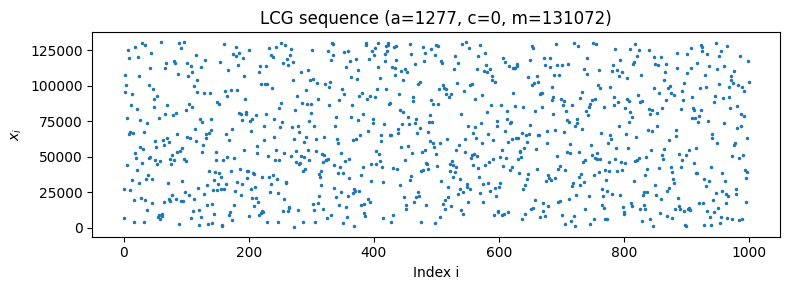

In [13]:
seed, a, c, m = 5, 1277, 0, 131072  # m = 2^17
random_ints_2 = lcg_random(seed, a, c, m, n=1000)
plt.figure(figsize=(8, 3))
plt.plot(random_ints_2, '.', markersize=3)
plt.title(f"LCG sequence (a={a}, c={c}, m={m})")
plt.xlabel("Index i")
plt.ylabel(r"$x_i$")
plt.tight_layout()
plt.show()

This one does not repeat as quickly, but a scatter plot like this alone
does not tell us whether it is *statistically* good — for that we need to
actually test its properties, which we do below.

### From integers to floats in $[0,1)$

Dividing the LCG's integer output by $m$ rescales it to the range $[0,1)$,
giving a real-valued pseudorandom number generator:

$$
u_i = \frac{x_i}{m} \in [0, 1).
$$

In [14]:
def lcg_random_float(seed, a, c, m, n):
    '''Generate n pseudorandom floats in [0, 1) using an LCG.'''
    random_numbers = []
    current = seed
    for _ in range(n):
        current = (a * current + c) % m
        random_numbers.append(current / m)
    return random_numbers

random_floats = lcg_random_float(5, 1277, 0, 131072, n=5)
print("First 5 floats:", [f"{x:.3f}" for x in random_floats])

First 5 floats: ['0.049', '0.207', '0.817', '0.730', '0.766']


### Your Turn: testing generator quality

A good PRNG for floats should produce numbers that are (1) **uniformly
distributed** over $[0,1)$ and (2) **uncorrelated** from one draw to the
next (knowing $u_i$ should tell you nothing about $u_{i+1}$). Use the
"Numerical Recipes" parameters below — a well-tested choice — to generate
10,000 numbers, then:

1. Compute the mean, min, and max (the mean should be close to 0.5).
2. Plot a histogram (it should look flat/uniform).
3. Make a scatter plot of consecutive pairs $(u_i, u_{i+1})$ — a good
   generator should fill the unit square with no visible pattern; a poor one
   often shows visible stripes or lattice structure (a well-known LCG defect
   related to correlations between successive outputs).

Mean: 0.5040 (expect ~0.5)
Min: 0.0003, Max: 0.9999


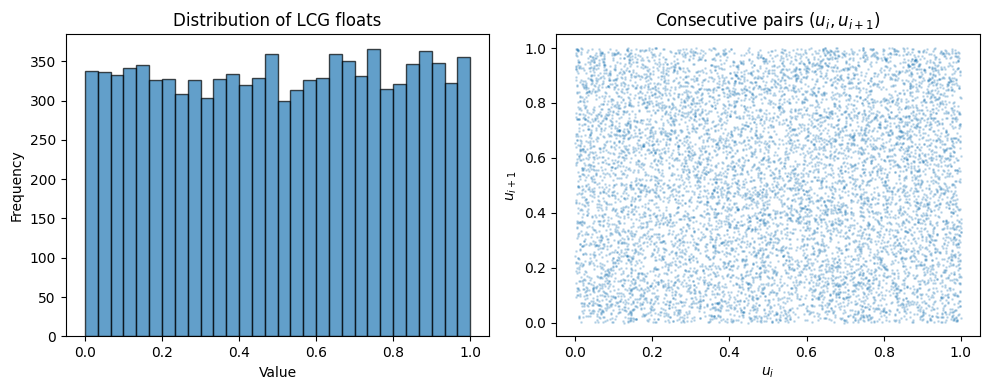

In [15]:
seed, a, c, m = 42, 1664525, 1013904223, 2**32  # Numerical Recipes parameters
many_numbers = lcg_random_float(seed, a, c, m, n=10000)

average = sum(many_numbers) / len(many_numbers)
print(f"Mean: {average:.4f} (expect ~0.5)")
print(f"Min: {min(many_numbers):.4f}, Max: {max(many_numbers):.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(many_numbers, bins=30, alpha=0.7, edgecolor='black')
plt.title("Distribution of LCG floats")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
x_vals = many_numbers[:-1]
y_vals = many_numbers[1:]
plt.scatter(x_vals, y_vals, s=1, alpha=0.2)
plt.title(r"Consecutive pairs $(u_i, u_{i+1})$")
plt.xlabel(r"$u_i$")
plt.ylabel(r"$u_{i+1}$")
plt.tight_layout()
plt.show()

For comparison, here are a few historically-used LCG parameter sets — some
notoriously bad (e.g. `RANDU`-style generators from the 1960s-70s show
strong correlations when plotted this way in 3D), others still in use
today in simplified forms.

In [16]:
parameter_sets = {
    'minstd': {'a': 16807, 'c': 0, 'm': 2**31 - 1},
    'glibc': {'a': 1103515245, 'c': 12345, 'm': 2**31},
    'borland': {'a': 22695477, 'c': 1, 'm': 2**32},
}

for name, params in parameter_sets.items():
    vals = lcg_random_float(seed, params['a'], params['c'], params['m'], n=5)
    print(f"{name}: {[f'{x:.6f}' for x in vals]}")

minstd: ['0.000329', '0.524587', '0.735424', '0.263306', '0.376224']
glibc: ['0.582308', '0.519819', '0.465976', '0.777037', '0.422865']
borland: ['0.221937', '0.867074', '0.456624', '0.328258', '0.787942']


In practice, `numpy.random` and Python's `random` module use much more
sophisticated algorithms (the Mersenne Twister, or NumPy's newer PCG64) with
astronomically long periods and far better statistical properties than a
simple LCG — but understanding the LCG gives you the right intuition for
*what "randomness quality" even means* and why you should never write your
own PRNG for real scientific work.

## Section 2: The Statistics of Random Processes

We now have a way to generate random numbers. But simulations built from
random numbers give a *different answer every time you run them* — so how do
we know how much to trust a given simulated result, and how many samples do
we need to collect to be confident in it? This is the central question of
this section, and the answer will apply to *every* stochastic simulation you
build for the rest of this course.

### 2.1 A random variable: the coin toss

Consider a coin toss modeled as a **Bernoulli random variable** $X$: it
takes the value $X=1$ ("heads") with probability $p$, and $X=0$ ("tails")
with probability $1-p$. For a fair coin, $p = 0.5$.

The **mean** (expectation value) of $X$ is defined as the probability-weighted
average of its possible outcomes:

$$
\mu \equiv E[X] = (1)\cdot p + (0)\cdot(1-p) = p.
$$

The **variance** measures the spread of $X$ about its mean, defined as
$\text{Var}(X) \equiv E[X^2] - (E[X])^2$. Since $X^2 = X$ for a
0/1-valued variable ($0^2=0$, $1^2=1$), $E[X^2] = E[X] = p$, so

$$
\sigma^2 \equiv \text{Var}(X) = p - p^2 = p(1-p).
$$

For a fair coin, $\mu = 0.5$ and $\sigma^2 = 0.25$ (so $\sigma = 0.5$).

### 2.2 Sample mean and sample variance: estimating $\mu$ and $\sigma^2$ from data

In a real simulation (or experiment) we don't get $\mu$ and $\sigma^2$
directly — we only get $N$ actual outcomes $x_1, x_2, \dots, x_N$, and we
**estimate** the true mean and variance from them:

$$
\bar{x}_N = \frac{1}{N}\sum_{i=1}^N x_i
\qquad\text{(sample mean)},
\qquad
s_N^2 = \frac{1}{N}\sum_{i=1}^N (x_i - \bar{x}_N)^2
\qquad\text{(sample variance)}.
$$

$\bar{x}_N$ and $s_N^2$ are themselves random — a *different* batch of $N$
coin tosses gives a *different* $\bar{x}_N$. The question we build up to
answering is: **how close should we expect $\bar{x}_N$ to be to the true
$\mu$, for a given $N$?**

In [17]:
np.random.seed(1)

def coin_toss(n):
    '''Simulate n fair-coin tosses; returns array of 0s (tails) and 1s (heads).'''
    return np.random.randint(0, 2, n)

for N in [5, 50, 500]:
    x = coin_toss(N)
    sample_mean = np.mean(x)
    sample_var = np.var(x)
    print(f"N={N:4d}:  sample mean = {sample_mean:.4f}  sample variance = {sample_var:.4f}  "
          f"(true mean=0.5, true variance=0.25)")

N=   5:  sample mean = 0.6000  sample variance = 0.2400  (true mean=0.5, true variance=0.25)
N=  50:  sample mean = 0.5200  sample variance = 0.2496  (true mean=0.5, true variance=0.25)
N= 500:  sample mean = 0.4820  sample variance = 0.2497  (true mean=0.5, true variance=0.25)


### 🧪 Your Turn

Using `coin_toss`, generate $N=20$ tosses with `np.random.seed(7)` set first.
Compute and print the sample mean and sample variance, and compare them to
the true values $\mu=0.5$, $\sigma^2=0.25$.

In [18]:
np.random.seed(7)
x20 = coin_toss(20)
sample_mean_20 = np.mean(x20)
sample_var_20 = np.var(x20)
print(f"N=20: sample mean = {sample_mean_20:.4f}, sample variance = {sample_var_20:.4f}")
print("True values: mean = 0.5, variance = 0.25")

N=20: sample mean = 0.5000, sample variance = 0.2500
True values: mean = 0.5, variance = 0.25


### 2.3 The Inverse Transform Method for Generating Random Variables

The inverse transform method provides a general way to generate random variables from a target distribution when its cumulative distribution function (CDF) is known and invertible. We start with a uniform random variable $U \sim \text{Uniform}(0, 1)$ and transform it using

$$
X = F_X^{-1}(U),
$$

where $F_X$ is the CDF of the desired distribution. We will apply the method to both discrete and continuous examples.


The **Inverse Transform Method** relies on the relationship between a distribution's CDF and its random variable. The steps are as follows:

1. **Start with a uniform random variable** $U \sim \text{Uniform}(0, 1)$.
2. **Define the target distribution’s CDF** $F_X(x)$.
3. **Invert the CDF** to obtain $F_X^{-1}(u)$.
4. **Transform the uniform random variable**:
   $$
   X = F_X^{-1}(U)
   $$
   The resulting random variable $X$ follows the desired distribution.

This works because the CDF maps the uniform range $[0, 1]$ to the range of the target random variable. Inverting this mapping ensures that the generated values follow the correct distribution.

We will first demonstrate this method for a discrete distribution (PMF) and then for a continuous distribution (PDF).


##### Discrete Distribution Example: Rolling a Die

Consider a random variable $X$ representing the outcome of a 6-sided die roll. The PMF is:
$$
P(X = x) =
\begin{cases} 
\frac{1}{6}, & x \in \{1, 2, 3, 4, 5, 6\} \\
0, & \text{otherwise}
\end{cases}
$$

The CDF is:
$$
F_X(x) = 
\begin{cases} 
0, & x < 1 \\
\frac{k}{6}, & x \in [k, k+1) \, \text{for } k = 1, 2, ..., 6 \\
1, & x \geq 6
\end{cases}
$$

Using the inverse transform method, we generate a uniform random variable $U \sim \text{Uniform}(0, 1)$ and map it to $X$ using the CDF intervals.


5


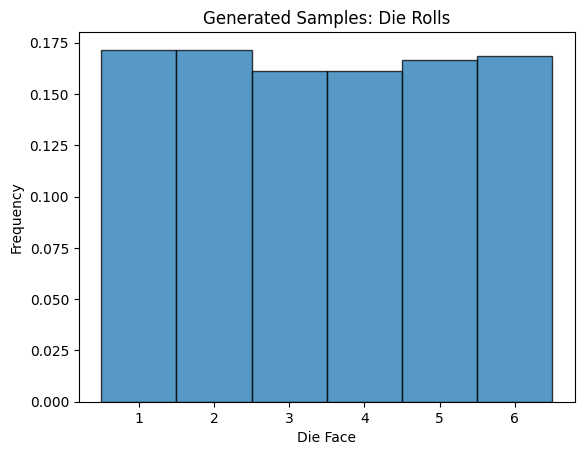

In [19]:
# Define CDF for a 6-sided die
die_faces = np.array([1, 2, 3, 4, 5, 6])
probabilities = np.array([1/6] * 6)  # Uniform probabilities

# Compute the cumulative probabilities (CDF)
cumulative_probs = np.cumsum(probabilities)

# Function to generate samples using the inverse transform method
def inverse_transform_discrete(cdf, values, n_samples):
    uniform_samples = np.random.uniform(0, 1, n_samples)
    generated_samples = []
    for u in uniform_samples:
        # Find the corresponding value for each uniform sample
        index = np.searchsorted(cdf, u)
        generated_samples.append(values[index])
    return np.array(generated_samples)

def ivt():
    F = 1/6 # initial probability mass
    p = 1/6 # probability mass as a function of a (fixed in this instance)
    a = 1 # outcome in the sample space
    U = np.random.uniform(0, 1) # Standard Uniform Draw
    while U > F: # Incrementing the CDF by the PMF until probability threshold is met
        F += p
        a += 1
    return a

print(ivt())

# Generate samples
n_samples = 10000
generated_die_rolls = inverse_transform_discrete(cumulative_probs, die_faces, n_samples)

# Plot histogram
plt.hist(generated_die_rolls, bins=np.arange(0.5, 7.5, 1), density=True, alpha=0.75, edgecolor='black')
plt.title('Generated Samples: Die Rolls')
plt.xlabel('Die Face')
plt.ylabel('Frequency')
plt.show()

##### Continuous Distribution Example: Exponential Distribution

For an exponential random variable $X$, the PDF is:
$$
f_X(x) = \lambda e^{-\lambda x}, \quad x \geq 0
$$

The CDF is:
$$
F_X(x) = 1 - e^{-\lambda x}
$$

The inverse CDF is:
$$
F_X^{-1}(u) = -\frac{\ln(1 - u)}{\lambda}
$$

Using the inverse transform method, we can generate exponential random variables by transforming $U \sim \text{Uniform}(0, 1)$.


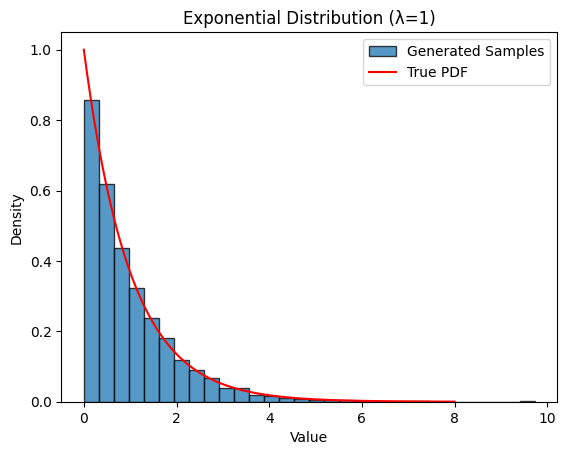

In [20]:
# Parameters for the exponential distribution
lam = 1.0  # Rate parameter (lambda)

# Inverse CDF function for the exponential distribution
def inverse_cdf_exponential(u, lam):
    return -np.log(1 - u) / lam

# Generate uniform samples and transform them
uniform_samples = np.random.uniform(0, 1, n_samples)
exponential_samples = inverse_cdf_exponential(uniform_samples, lam)

# Plot histogram
plt.hist(exponential_samples, bins=30, density=True, alpha=0.75, edgecolor='black', label='Generated Samples')

# Overlay the true PDF
x = np.linspace(0, 8, 1000)
pdf = lam * np.exp(-lam * x)
plt.plot(x, pdf, 'r-', label='True PDF')
plt.title('Exponential Distribution (λ=1)')
plt.xlabel('Value')
plt.ylabel('Density')
plt.legend()
plt.show()

### 2.4 Putting it to use: is a coin fair?

We now have the tools to properly answer a question posed at the start of
this kind of statistical reasoning:

> A coin was tossed 30 times. It came up heads 22 times. Is this a fair coin?

**Step 1 — quick CLT-based estimate.** Under the null hypothesis that the
coin is fair ($p=0.5$, $n=30$ tosses), the expected number of heads is
$\mu_S = np = 15$, with standard deviation $\sigma_S = \sqrt{np(1-p)} =
\sqrt{30 \times 0.25} \approx 2.74$ (this is exactly the $\text{Var}(S) =
N\sigma^2$ result from Section 3.4, applied to the *sum* rather than the
mean). Observing 22 heads is

$$
z = \frac{22 - 15}{2.74} \approx 2.6
$$

standard deviations above the expected value — already suggestively rare
for a Gaussian, whose tail probability beyond $2.6\sigma$ is small.

**Step 2 — exact simulation.** Rather than relying only on the Gaussian
approximation (which is only exact in the $N\to\infty$ limit), let's directly
simulate: repeat "toss a fair coin 30 times" 100,000 times, and measure what
fraction of those trials produce 22 or more heads.

In [21]:
np.random.seed(66)
n_experiments = 100000
sample_size = 30

number_heads = np.random.randint(0, 2, size=(n_experiments, sample_size)).sum(axis=1)
p_value = np.mean(number_heads >= 22)

print(f"P(22 or more heads out of 30, fair coin) = {p_value:.4f}")
print("Significance level alpha = 0.01")
if p_value < 0.01:
    print("This is a rare event under the fair-coin hypothesis -> the coin is likely unfair.")
else:
    print("This is not a rare event -> no strong evidence the coin is unfair.")

P(22 or more heads out of 30, fair coin) = 0.0083
Significance level alpha = 0.01
This is a rare event under the fair-coin hypothesis -> the coin is likely unfair.


Since $p \approx 0.008 < \alpha = 0.01$, observing 22 (or more) heads out
of 30 fair-coin tosses is rare enough that we reject the "fair coin"
hypothesis at the 1% significance level. Notice that the exact simulated
p-value ($\approx 0.008$) is close to, but not identical to, the quick
Gaussian estimate from Step 1 — the CLT is an approximation that gets better
for larger $N$, while the direct simulation is exact up to statistical noise
(which is itself controlled by *how many* of the 100,000 repeated
experiments we ran — the same SEM logic once again).

## Part C — Exercises

## ⚛️ Physics Application — Worked Example: Radioactive Decay

We now apply everything above to a genuine physical stochastic process:
the decay of a radioactive sample.

### Step 1: Analysis

An unstable nucleus decays at a random time, but every nucleus of a given
species has the same **decay constant** $\lambda$ (units of $1/\text{time}$):
in any short interval $\Delta t$, each surviving nucleus decays
independently with probability

$$
p = \lambda\, \Delta t.
$$

**Discrete-to-continuum limit.** If we start with $N_0$ nuclei and step
forward in increments of $\Delta t$, the *expected* number of survivors after
one step is $N_0(1-p) = N_0(1-\lambda\Delta t)$. After $n$ steps (so
$t = n\Delta t$), the expected number of survivors is

$$
N(t) \approx N_0 (1-\lambda\Delta t)^n = N_0\left(1 - \frac{\lambda t}{n}\right)^n.
$$

Taking the continuum limit $\Delta t \to 0$ (i.e. $n\to\infty$ at fixed
$t=n\Delta t$) and using the standard limit
$\lim_{n\to\infty}\left(1-\frac{x}{n}\right)^n = e^{-x}$:

$$
N(t) \longrightarrow N_0\, e^{-\lambda t}.
$$

This is exactly the same "replace a continuous process by many small
discrete steps, then let the step size shrink" idea used to derive the
Euler method in Kinematics Lecture 1 — there we discretized a *deterministic*
rate equation; here we discretize a *stochastic* one, but the limiting
argument is identical. The **half-life** $t_{1/2}$ (time for half the sample
to decay) follows directly from $N(t_{1/2}) = N_0/2$:

$$
t_{1/2} = \frac{\ln 2}{\lambda}.
$$

### Step 2: Algorithm

1. Start with $N_0$ nuclei and choose a small time step $\Delta t$.
2. At each step, draw one uniform random number per *surviving* nucleus; a
   nucleus decays if its random number is less than $p=\lambda\Delta t$.
3. Remove the decayed nuclei and record the number remaining.
4. Repeat until the desired total simulation time is reached.
5. Compare the simulated decay curve to the analytic $N_0 e^{-\lambda t}$.

### Step 3: Implementation

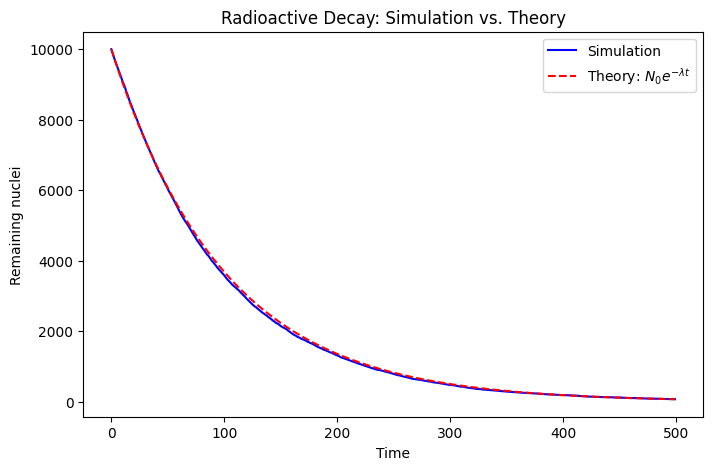

Theoretical half-life: 69.3 time units


In [22]:
def simulate_decay(N0, lam, dt, total_time):
    '''
    Simulate radioactive decay of N0 nuclei with decay constant lam.

    Parameters
    ----------
    N0 : int -- initial number of nuclei
    lam : float -- decay constant (1/time)
    dt : float -- time step
    total_time : float -- total simulated time

    Returns
    -------
    time_points : ndarray
    remaining : ndarray -- number of surviving nuclei at each time point
    '''
    time_points = np.arange(0, total_time, dt)
    remaining = np.zeros(len(time_points))
    remaining[0] = N0
    p = lam * dt

    for i in range(1, len(time_points)):
        n_survivors = int(remaining[i-1])
        decays = np.random.rand(n_survivors) < p
        remaining[i] = n_survivors - np.sum(decays)

    return time_points, remaining

np.random.seed(77)
N0 = 10000
lam = 0.01
dt = 1.0
total_time = 500

time_points, remaining = simulate_decay(N0, lam, dt, total_time)
theoretical = N0 * np.exp(-lam * time_points)

plt.figure(figsize=(8, 5))
plt.plot(time_points, remaining, label='Simulation', color='blue')
plt.plot(time_points, theoretical, label=r'Theory: $N_0 e^{-\lambda t}$', linestyle='--', color='red')
plt.xlabel("Time")
plt.ylabel("Remaining nuclei")
plt.title("Radioactive Decay: Simulation vs. Theory")
plt.legend()
plt.show()

half_life_theory = np.log(2) / lam
print(f"Theoretical half-life: {half_life_theory:.1f} time units")

### Step 4: Results and Discussion

The simulation tracks the theoretical exponential closely, but not
perfectly — at any instant, the simulated `remaining` count is itself a
single realization of a random process, so it fluctuates around the
theoretical curve exactly the way a sample mean fluctuates around $\mu$. In
fact, as we will see in the next section, the size of this fluctuation
follows its own predictable statistical law.

Two discussion points worth noting:
- The fluctuations are *relatively* larger when few nuclei remain (late
  time) than when many remain (early time) — we'll see exactly why in the
  Poisson statistics discussion below.
- Larger $N_0$ makes the simulation track the theoretical curve more
  tightly in a *relative* sense, for the same $1/\sqrt{N}$-type reason
  established in Section 3.

## Part D — Computational Problems

### Radioactive-decay statistics

Students will **work in pairs** to develop, implement, and analyze their solutions.

### Level 1: Guided implementation

Instead of tracking the whole decay curve, consider a single fixed observation window of length $\Delta t_{\text{obs}}$, and ask: **how many of the $N_0$ nuclei decay in that window?** Each nucleus decays independently with probability

$$
q = 1 - e^{-\lambda \Delta t_{\text{obs}}}.
$$

Simulate this experiment repeatedly and compare the histogram of decay counts with a Poisson distribution having mean $\mu = N_0q$. Use the existing code as a starting point. Check that the simulated mean and standard deviation agree with the predictions, and explain the relative fluctuation $1/\sqrt{\mu}$.



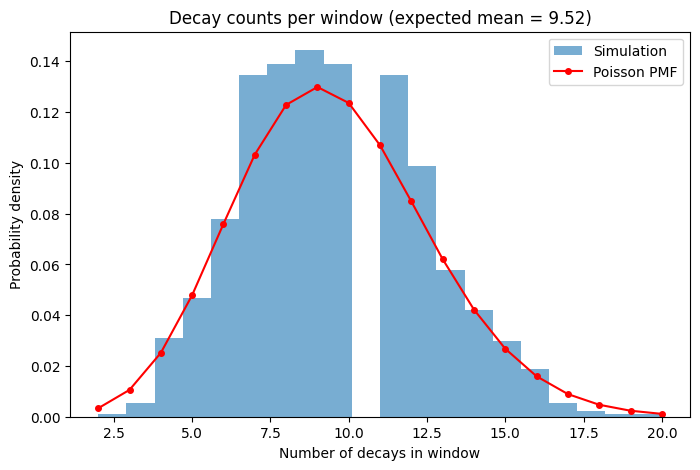

In [23]:
np.random.seed(88)
from scipy.stats import poisson

N0_obs = 100
lam_obs = 0.01
dt_obs = 10.0
n_trials = 1000

q = 1 - np.exp(-lam_obs * dt_obs)
expected_decays = N0_obs * q

decay_counts = np.zeros(n_trials)
for i in range(n_trials):
    decays = np.random.rand(N0_obs) < q
    decay_counts[i] = np.sum(decays)

plt.figure(figsize=(8, 5))
plt.hist(decay_counts, bins=20, density=True, alpha=0.6, label='Simulation')

x = np.arange(poisson.ppf(0.001, expected_decays), poisson.ppf(0.999, expected_decays) + 1)
plt.plot(x, poisson.pmf(x, expected_decays), 'ro-', label='Poisson PMF', markersize=4)
plt.xlabel("Number of decays in window")
plt.ylabel("Probability density")
plt.title(f"Decay counts per window (expected mean = {expected_decays:.2f})")
plt.legend()
plt.show()

### Level 2: Numerical investigation

Repeat the radioactive-decay counting experiment for several values of $N_0$, $\lambda$, and $\Delta t_{\text{obs}}$. For each case, compare the simulated mean and variance with the Poisson predictions

$$
\mu = N_0q, \qquad \operatorname{Var}(n_{\text{decay}})=\mu.
$$

Present the results in a table and include a histogram of the counts with the predicted Poisson probability mass function overlaid. Explain how the relative fluctuation changes as the expected number of decays increases.


### Level 3: Statistical analysis

Use the binomial model for the number of decays in a fixed observation window to derive its mean and variance. Explain why the Poisson distribution is obtained when $N_0$ is large and the single-nucleus decay probability $q$ is small while $\mu=N_0q$ remains fixed.

Test this approximation numerically by varying $N_0$ and $q$. Identify when the Poisson model becomes inaccurate, and connect the observed differences to the assumptions of independence, small decay probability, and finite sample size. Record the reasoning behind your conclusions, not only the numerical output.


A key property of the Poisson distribution is that its variance equals
its mean: $\text{Var}(n_{\text{decay}}) = \mu_{\text{decay}}$, so its
standard deviation is $\sqrt{\mu_{\text{decay}}}$. This is the *same*
"fluctuations shrink relative to the signal as the count grows" idea as the
$\text{SEM}=\sigma/\sqrt{N}$ result from Section 3.4: the **relative**
fluctuation in a Poisson count is

$$
\frac{\sqrt{\mu_{\text{decay}}}}{\mu_{\text{decay}}} = \frac{1}{\sqrt{\mu_{\text{decay}}}},
$$

which shrinks as the expected count grows. This is exactly the "$\sqrt{N}$
counting statistics" you may already have encountered with a Geiger counter
in an intro or modern physics lab: the more counts you accumulate, the
smaller your *relative* statistical uncertainty — the absolute uncertainty
in a raw count of $\mu$ decays is $\sqrt{\mu}$, but as a fraction of $\mu$
that shrinks as $1/\sqrt{\mu}$.

In [24]:
print(f"Mean decay count: {np.mean(decay_counts):.2f} (predicted: {expected_decays:.2f})")
print(f"Std dev of decay count: {np.std(decay_counts):.2f} (predicted sqrt(mean): {np.sqrt(expected_decays):.2f})")
print(f"Relative fluctuation (std/mean): {np.std(decay_counts)/np.mean(decay_counts):.3f}")

Mean decay count: 9.47 (predicted: 9.52)
Std dev of decay count: 2.88 (predicted sqrt(mean): 3.08)
Relative fluctuation (std/mean): 0.305


## ✅ Lecture 2 Summary

- **Pseudorandom generators**: deterministic algorithms (e.g. the linear
  congruential generator $x_i = (ax_{i-1}+c)\bmod m$) that produce sequences
  that look random; quality is judged by uniformity of the distribution and
  absence of correlation between successive outputs, not just by having a
  large modulus.
- **Inverse Transform Method**: technique for generating random variables from any distribution with a known and invertible CDF. The method apply to discrete and continuous distributions.
- **Sample mean and sample variance** are estimators of the true mean $\mu$
  and variance $\sigma^2$ of a random process, computed from a finite batch
  of $N$ samples.
- **Radioactive decay**: a genuine physical stochastic process, where the
  discrete per-nucleus decay probability $p=\lambda\Delta t$ gives the
  continuum law $N(t)=N_0 e^{-\lambda t}$ in the $\Delta t\to 0$ limit, and
  the number of decays in a fixed window follows Poisson statistics with the
  same "$1/\sqrt{N}$-type" relative-fluctuation behavior.

These statistical tools — sample mean/variance, SEM, and choosing $N$ for a
target precision — are exactly what you will need in Lecture 2 to interpret
random-walk simulations, and again later in the course for Monte Carlo
methods and the Ising model.


(Extra) important concepts :

- **Law of Large Numbers**: the sample mean converges to the true mean as
  $N\to\infty$; the *distribution* of the sample mean across repeated
  experiments narrows as $N$ grows.
- **Central Limit Theorem**: sums (and means) of many i.i.d. random
  variables approach a Gaussian distribution, regardless of the shape of the
  underlying distribution.
- **Standard Error of the Mean**: $\text{SEM} = \sigma/\sqrt{N}$ — derived
  directly from the independence of the samples — tells us how precisely we
  can trust an average computed from $N$ samples, and lets us invert for the
  $N$ needed to hit a target precision.